# Project work part 3 - Data quality

- Author: Mehdi Jamali


## Links
- [GitHub repository](https://github.com/Mehdij1511/IND320-Mehdij1511)

- [Streamlit app](https://ind320mehdij1511.streamlit.app/)

- Video: The screencast will be recorded and added on 11 November, after the Open-Meteo request limit resets. It could not be completed before today's submission deadline.

## Declaration of AI usage

I used the following AI tools while working on this project:
- **GitHub Copilot:**
    - Used for code completion, suggestions, and feedback during development.
    - Also used to help implement and test the Part 3 ERA5 downloader, data-quality analyses, Streamlit pages, and caching safeguards.
- **Gemini:**
    - Used for coding assistance and for finding relevant functions and methods.
- **NotebookLM (Gemini):**
    - Used as a research assistant to answer questions and explain topics related to the project.

I reviewed and adapted the suggestions, and tested the code before using it in the project.

**The AI tools were used within the guidelines of "K3 - Full use of AI" at NMBU.**

## Work log

I worked on Part 3 in the temporary `part3` branch so the changes could remain separate from `main` during peer review. I started by loading the NVE region shapefile with GeoPandas. The file contains the regions `RM`, `RN`, `RS`, `RV`, and `RØ` in a projected coordinate system. I generated reproducible random samples inside each polygon and converted them to longitude and latitude for the weather API. I used 1,000 sample points per region and verified the sample counts and polygon membership. I then mapped the electricity areas as NO1=RS+RØ, NO2=RS, NO3=RM, NO4=RM+RN, and NO5=RV.

The main technical challenge was designing a reliable ERA5 downloader. The first implementation sent repeated list-valued parameters for dates, variables, model, and timezone. Open-Meteo rejected that request format. I corrected it so longitude and latitude are combined arrays with up to 100 coordinates per request, while the other parameters are shared scalar values. Several grid points can represent the same 0.25-degree ERA5 cell, so I request each cell once and weight its contribution by the number of sample points. Successful responses are cached locally, and the implementation can also use the shared MongoDB cache.

The complete NO3 download was blocked by external API limits. At the final check, 155 of 286 grid cells had full-year responses. The first large requests produced `ReadTimeout` errors. After the request format was corrected, Streamlit Cloud returned HTTP 400 because 100 coordinates, two hourly variables, and a complete year still exceeded Open-Meteo's data-volume limit for one request. An attempted 14-day-window workaround generated many calls and encountered API quota limits, so I removed that approach.

For the data-quality work, I implemented the DCT high-pass SATV/SPC precipitation analysis, Local Outlier Factor temperature anomaly detection, STL decomposition, and a spectrogram for reservoir filling. The reservoir STL and spectrogram cell ran successfully. The weather-analysis cell could not run because `weather_no3_2024` was never created after the failed download. The Streamlit app was updated with a reservoir-seasonality page and a weather-outliers page, using tabs, area selection, caching, download controls, and readable API error messages. I tested the analysis functions with mocked data and tested the request and timeout flows locally. I also removed the explicit Fiona dependency after Streamlit Cloud failed to build it without GDAL; GeoPandas uses the available Pyogrio backend instead. I used GitHub Copilot, Gemini, and NotebookLM for explanations and coding suggestions, and reviewed and tested the resulting changes myself. I will submit today without the screencast because the API limit prevented a complete live demonstration; the screencast is planned for 11 November after the limit resets.

On 12 November, I followed up on the lecturer's advice to combine coordinates in Open-Meteo requests. The API rejected full-year requests containing 100 locations as too large, so I reused the existing full-year cache and fetched the remaining grid cells in five-location full-year batches, keeping precipitation and temperature together. The final cache-first run completed successfully: all 286 NO3 grid cells contributed to a complete 2024 series with 8,784 unique hourly observations and no missing precipitation or temperature values. I saved the complete area series locally. I then ran both weather analyses on the complete data: the precipitation SPC analysis identified 651 outliers (7.41%), and Local Outlier Factor identified 88 temperature anomalies (1.00%). The notebook download and analysis cells were rerun successfully from the completed cache.


## Load and check the NVE region shapefile

I keep the five region codes separate so each sampled location can be traced back to its source polygon. A fixed random seed makes the same sample reproducible.

## Inspect region names and sample locations

The helper reads the shapefile, checks the region codes, and creates the sample locations.

In [1]:
# Find the project root so imports work from either notebook location.
%matplotlib inline
from pathlib import Path
import sys
import pandas as pd

project_root = Path.cwd()
if not (project_root / "part3_data.py").is_file():
    project_root = project_root.parent
if not (project_root / "part3_data.py").is_file():
    raise FileNotFoundError("Could not find part3_data.py in the project.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Load the regions and take a reproducible sample from each one.
from part3_data import load_nve_regions, sample_region_locations

regions = load_nve_regions()
region_coordinates = sample_region_locations(
    regions,
    samples_per_region=1000,
    random_seed=42,
)

sample_counts = {code: len(points) for code, points in region_coordinates.items()}
assert set(sample_counts) == {"RM", "RN", "RS", "RV", "RØ"}
assert all(count == 1000 for count in sample_counts.values())

print(regions[["REGIONNAVN"]])
print("Sampled locations per region:", sample_counts)


               REGIONNAVN
REGION                   
RM      Region Midt-Norge
RN            Region Nord
RS             Region Sør
RV            Region Vest
RØ             Region Øst
Sampled locations per region: {'RM': 1000, 'RN': 1000, 'RS': 1000, 'RV': 1000, 'RØ': 1000}


## Download hourly ERA5 data for NO3

I map the electricity areas to the NVE regions as follows: NO1 uses RS and RØ, NO2 uses RS, NO3 uses RM, NO4 uses RM and RN, and NO5 uses RV. In other words, East is RS+RØ and North is RM+RN. For each region, the downloader starts with 1,000 sampled locations. If several samples fall in the same 0.25-degree ERA5 grid cell, it requests that cell once and weights its contribution by the number of sample points there. Completed API batches and validated full area/year results are cached locally so later runs can reuse them.

Each archive request combines up to five grid-cell coordinates and retrieves the full selected hourly time series, with precipitation and temperature requested together. Open-Meteo permits up to 100 locations, but rejected this full-year ERA5 request at 100 locations as too much data; successful cached full-year responses used groups of five. Existing complete location batches are loaded first. The complete 2024 NO3 series has now been cached after validating all 8,784 hourly timestamps and both weather variables.

In [2]:
from part3_data import download_era5_data

# Request all hourly weather data for 2024; the downloader checks completeness.
weather_no3_2024 = download_era5_data(
    region_identifier="NO3",
    start_date="2024-01-01",
    end_date="2024-12-31",
    samples_per_region=1000,
    random_seed=42,
)
assert len(weather_no3_2024) == 8784
assert weather_no3_2024["time"].is_monotonic_increasing
assert weather_no3_2024["time"].is_unique
assert weather_no3_2024[["precipitation", "temperature_2m"]].notna().all().all()

# Save the complete series locally so future runs can reuse it.
weather_cache_file = project_root / "data" / "era5_cache" / "NO3_ERA5_2024.csv"
weather_cache_file.parent.mkdir(parents=True, exist_ok=True)
weather_no3_2024.to_csv(weather_cache_file, index=False)

print(f"Downloaded {len(weather_no3_2024):,} hourly observations.")
print(f"Cached complete area series at {weather_cache_file}.")
weather_no3_2024.head()


Downloaded 8,784 hourly observations.
Cached complete area series at C:\Users\cyrgo\Documents\GitHub\IND320-Mehdij1511\data\era5_cache\NO3_ERA5_2024.csv.


,time,precipitation,temperature_2m
0,2024-01-01 00:00:00+00:00,0.0012,-7.4082
1,2024-01-01 01:00:00+00:00,0.0020,-7.4831
2,2024-01-01 02:00:00+00:00,0.0020,-7.3455
3,2024-01-01 03:00:00+00:00,0.0021,-7.2439
4,2024-01-01 04:00:00+00:00,0.0007,-7.1100


## Precipitation outliers and temperature anomalies

The precipitation analysis uses a high-pass DCT to calculate SATV and robust SPC limits, while the temperature analysis identifies anomalies with Local Outlier Factor. SATV is used to classify outliers but is not plotted.

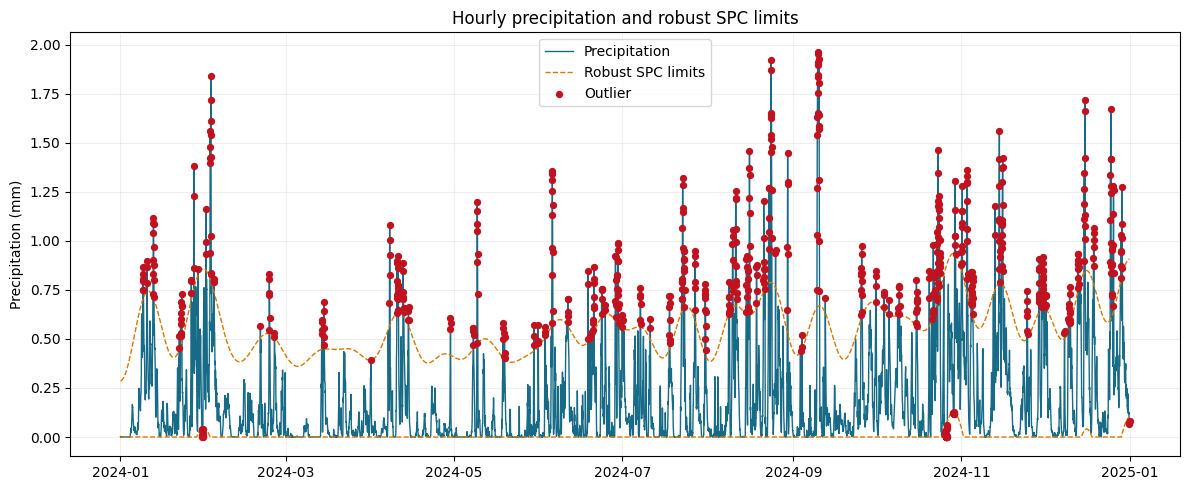

observations          8784.000000
outliers               651.000000
outlier_percentage       7.411202
low_outliers            43.000000
high_outliers          608.000000
satv_median             -0.041378
satv_robust_sigma        0.134550
Name: Precipitation SPC summary, dtype: float64

,time,precipitation,lower_limit,upper_limit,direction
0,2024-01-09 03:00:00+00:00,0.7955,0.0,0.701758,high
1,2024-01-09 04:00:00+00:00,0.8644,0.0,0.703401,high
2,2024-01-09 05:00:00+00:00,0.8324,0.0,0.705013,high
3,2024-01-09 06:00:00+00:00,0.8059,0.0,0.706594,high
4,2024-01-09 07:00:00+00:00,0.7487,0.0,0.708142,high
5,2024-01-09 08:00:00+00:00,0.7472,0.0,0.709659,high
6,2024-01-10 14:00:00+00:00,0.7864,0.0,0.739405,high
7,2024-01-10 15:00:00+00:00,0.8984,0.0,0.739850,high
8,2024-01-10 16:00:00+00:00,0.8654,0.0,0.740259,high
9,2024-01-12 18:00:00+00:00,0.7295,0.0,0.716073,high


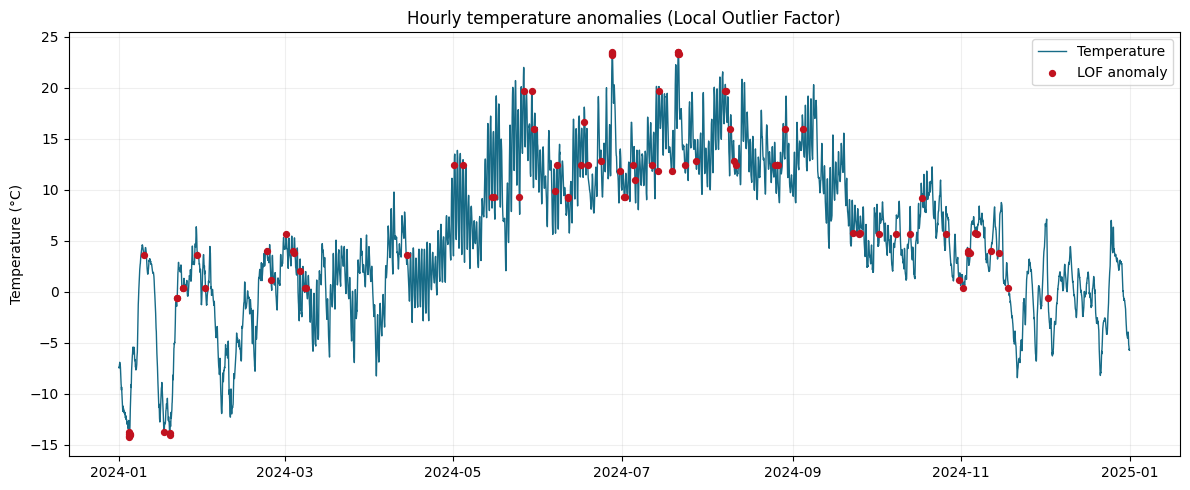

observations          8784.000000
anomalies               88.000000
anomaly_percentage       1.001821
contamination            0.010000
Name: Temperature LOF summary, dtype: float64

,time,temperature_2m,lof_score
0,2024-01-04 15:00:00+00:00,-13.7086,-1.214968
1,2024-01-04 16:00:00+00:00,-13.9353,-1.420903
2,2024-01-04 17:00:00+00:00,-14.1138,-1.621457
3,2024-01-04 18:00:00+00:00,-14.2387,-1.837646
4,2024-01-04 19:00:00+00:00,-14.0516,-1.541203
5,2024-01-04 20:00:00+00:00,-13.9157,-1.402202
6,2024-01-10 04:00:00+00:00,3.5808,-1.274921
7,2024-01-17 09:00:00+00:00,-13.7132,-1.218263
8,2024-01-19 08:00:00+00:00,-13.8386,-1.330507
9,2024-01-19 09:00:00+00:00,-13.9977,-1.482429


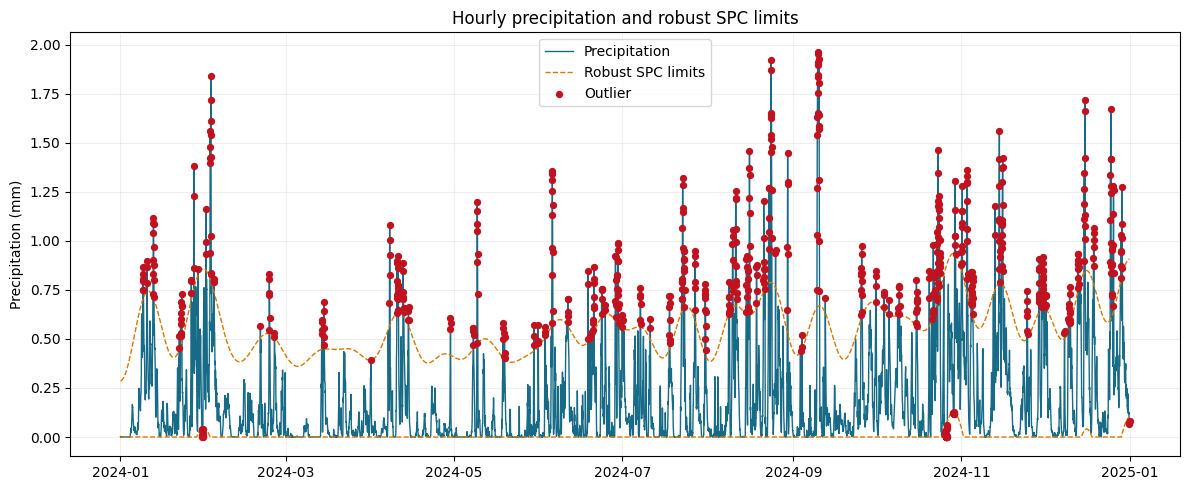

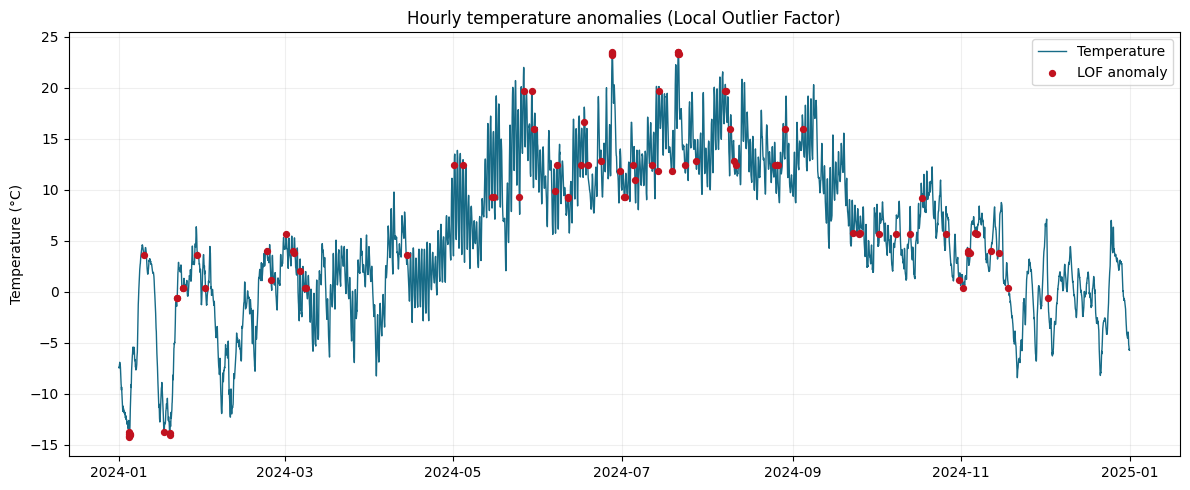

In [3]:
from IPython.display import display
from part3_analysis import plot_precipitation_outliers, plot_temperature_anomalies

# Use DCT-derived SATV to classify outliers; the plot shows precipitation and limits.
precipitation_figure, precipitation_summary, precipitation_outliers = (
    plot_precipitation_outliers(
        weather_no3_2024,
        frequency_cutoff=52,
        n_standard_deviations=3,
    )
)
assert precipitation_summary["observations"] == len(weather_no3_2024)
assert len(precipitation_outliers) == precipitation_summary["outliers"]
display(precipitation_figure)
display(pd.Series(precipitation_summary, name="Precipitation SPC summary"))
display(precipitation_outliers.head(10))

# Use Local Outlier Factor to flag unusual temperatures (1% expected by default).
temperature_figure, temperature_summary, temperature_anomalies = (
    plot_temperature_anomalies(weather_no3_2024, contamination=0.01)
)
assert temperature_summary["observations"] == len(weather_no3_2024)
assert len(temperature_anomalies) == temperature_summary["anomalies"]
display(temperature_figure)
display(pd.Series(temperature_summary, name="Temperature LOF summary"))
display(temperature_anomalies.head(10))


**Execution note:** The full NO3 ERA5 series is now available in the local cache. The precipitation SPC and temperature LOF analyses ran successfully on all 8,784 hourly observations.

## Reservoir-filling STL and spectrogram

Weekly filling levels for electricity area 3 (NO3) are retrieved from Magasinstatistikk. STL and the spectrogram use the same time series.

2026-11-10 21:59:18.563 No runtime found, using MemoryCacheStorageManager
2026-11-10 21:59:18.565 No runtime found, using MemoryCacheStorageManager
2026-11-10 21:59:18.567 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


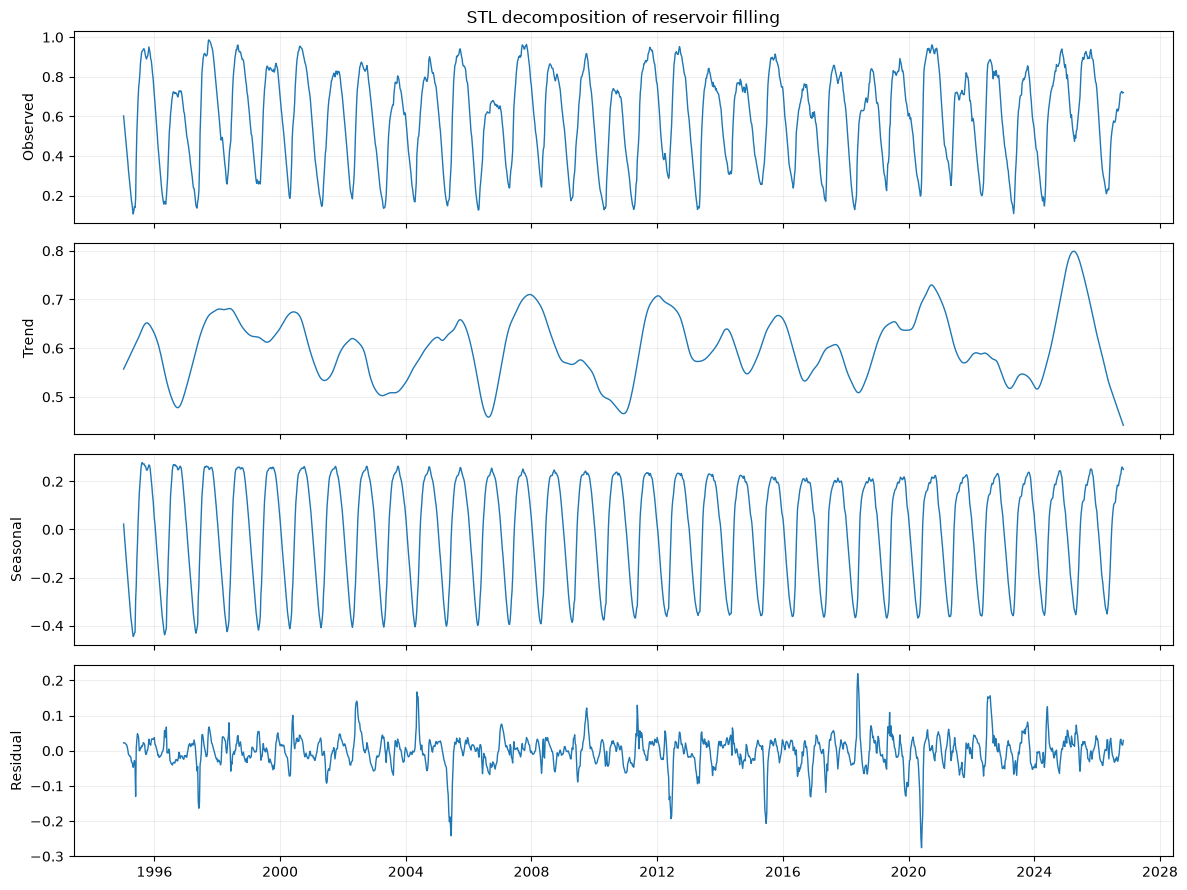

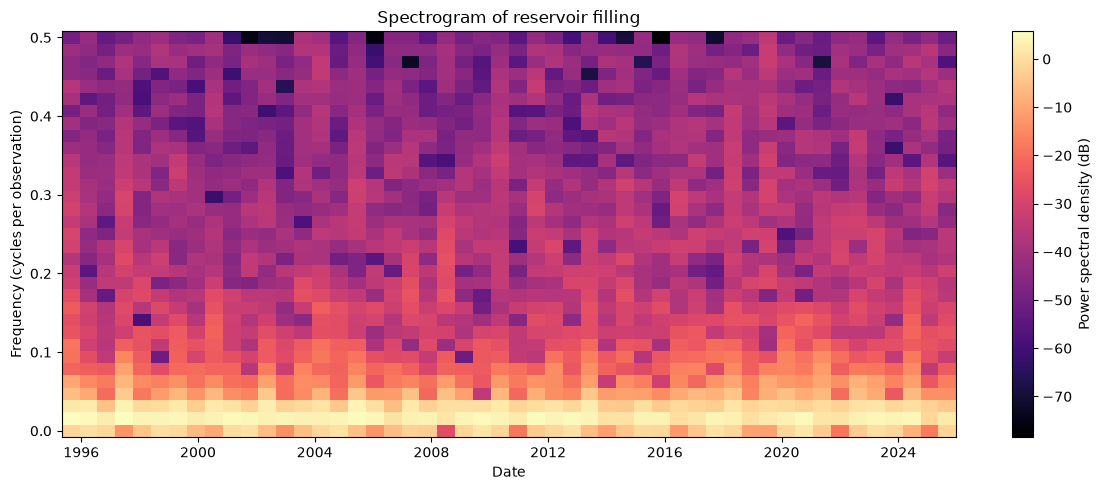

In [5]:
import matplotlib.pyplot as plt
from nve_data import load_reservoir_data
from part3_analysis import plot_spectrogram, plot_stl_decomposition

# Use the NO3 reservoir-filling series (area 3) for this analysis.
reservoir_data = load_reservoir_data()
no3_reservoir_data = reservoir_data.loc[
    (reservoir_data["omrType"] == "EL") & (reservoir_data["omrnr"] == 3)
].sort_values("dato_Id")
no3_filling = no3_reservoir_data.set_index("dato_Id")["fyllingsgrad"]

stl_figure, stl_result = plot_stl_decomposition(
    no3_filling,
    seasonal=13,
    trend=53,
    robust=True,
)
assert len(stl_result.trend) == len(no3_filling)
display(stl_figure)
plt.close(stl_figure)

spectrogram_figure = plot_spectrogram(
    no3_filling,
    window_length=64,
    window_overlap=32,
)
assert spectrogram_figure.axes
display(spectrogram_figure)
plt.close(spectrogram_figure)
